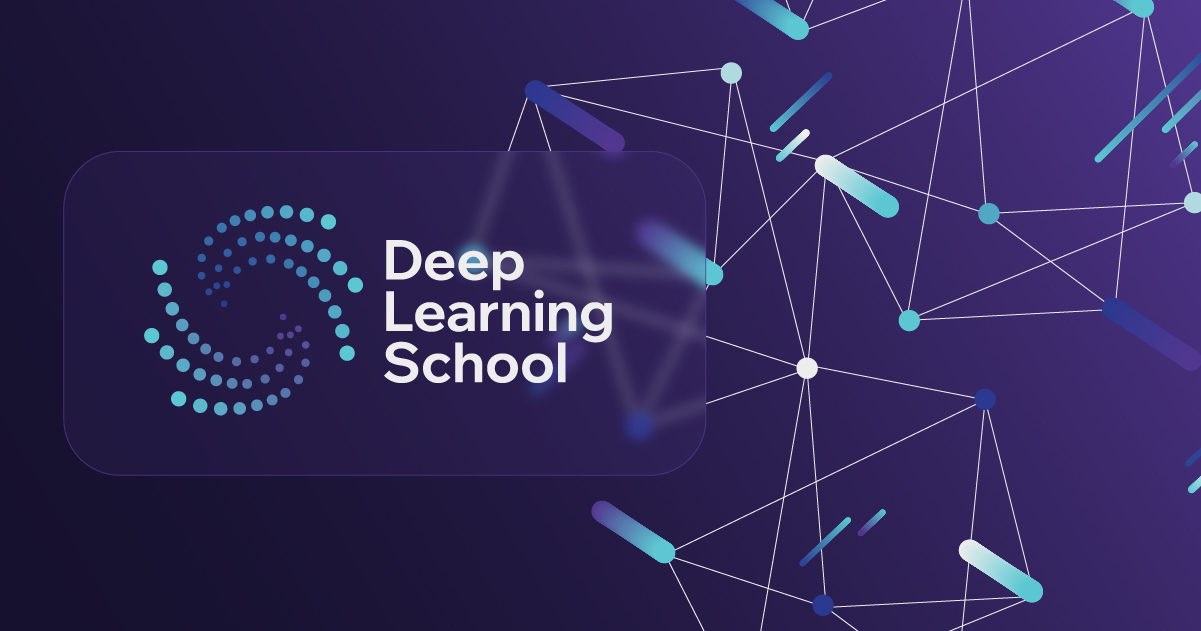


# Домашнее задание "Варианционные автоэнкодеры"

В этом домашнем задании вам предстоит реализовать несколько версий автоэнкодера для работы с изображениями.

Вы научитесь добавлять улыбку на фотографии людей, изменяя их исходное выражение лица с помощью обученной модели. А также, обучите ваш автоэнкодер генерировать изображения рукописных цифр.

# Часть 1. Vanilla Autoencoder (10 баллов)

## 1.1. Подготовка данных (1 балл)


Перед тем, как начинать работу с моделями нужно подготовить данные.

In [ ]:
import numpy as np
from torch.autograd import Variable
from torchvision import datasets
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data_utils
import torch
import matplotlib.pyplot as plt

import os
import pandas as pd
import skimage.io
from skimage.transform import resize

import imageio
from PIL import Image
import kagglehub

%matplotlib inline

В этом задании вам предстоить работать с датасетом [LFW (Labeled Faces in the Wild)](https://datasets.activeloop.ai/docs/ml/datasets/lfw-dataset/#:~:text=What%20is%20LFW%20Dataset%3F,commercial%20algorithms%20prior%20to%20release).

In [ ]:
# Скачиваем картинки
images_path = kagglehub.dataset_download("jessicali9530/lfw-dataset")
print("Path to dataset files:", images_path)

In [ ]:
# Скачиваем атрибуты
attrs_path = kagglehub.dataset_download("averkij/lfw-attributes")
print("Path to dataset files:", attrs_path)

In [ ]:
DATASET_PATH ="/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled/"
ATTRIBUTES_PATH = "/kaggle/input/lfw-attributes/lfw_attributes.txt"

In [ ]:
def fetch_dataset(dx=80, dy=80, dimx=45, dimy=45):

    df_attrs = pd.read_csv(ATTRIBUTES_PATH, sep='\t', skiprows=1,)
    df_attrs = pd.DataFrame(df_attrs.iloc[:, :-1].values, columns = df_attrs.columns[1:])

    photo_ids = []
    for dirpath, dirnames, filenames in os.walk(DATASET_PATH):
        for fname in filenames:
            if fname.endswith(".jpg"):
                fpath = os.path.join(dirpath, fname)
                photo_id = fname[:-4].replace('_', ' ').split()
                person_id = ' '.join(photo_id[:-1])
                photo_number = int(photo_id[-1])
                photo_ids.append({'person': person_id,'imagenum': photo_number, 'photo_path': fpath})

    photo_ids = pd.DataFrame(photo_ids)
    df = pd.merge(df_attrs,photo_ids,on=('person', 'imagenum'))

    assert len(df) == len(df_attrs), "Потеряны данные при объединении датафреймов!"

    images = df['photo_path'].apply(imageio.imread)\
                                .apply(lambda img:img[dy:-dy, dx:-dx])\
                                .apply(lambda img: np.array(Image.fromarray(img).resize([dimx, dimy])) )

    images = np.stack(images.values).astype('uint8')
    attrs = df.drop(["photo_path","person","imagenum"],axis=1)

    return images, attrs

In [ ]:
# Обратите внимание, что датасет представляет собой не только картинки, но и атрибуты
# Атрибуты понадобятся в конце этого задания

images, attrs = fetch_dataset()


Разбейте датасет изображений и атрибутов на train и val, выведите несколько картинок в output, чтобы посмотреть, как они выглядят, и приведите картинки к тензорам pytorch, чтобы можно было скормить их сети:

In [ ]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset, DataLoader

In [ ]:
images_train, images_val, attrs_train, attrs_val = train_test_split(
    images, attrs, test_size=0.2, random_state=42
)

# 2. Выводим несколько картинок, чтобы посмотреть на них
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(images_train[i])
    ax.axis('off')
plt.suptitle("Примеры лиц из LFW", fontsize=16)
plt.show()

# 3. Приводим картинки к тензорам PyTorch
# Исходный формат: (N, Height, Width, Channels) со значениями [0, 255] типа uint8
# Формат PyTorch: (N, Channels, Height, Width) со значениями [0.0, 1.0] типа float32
X_train = torch.tensor(images_train, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
X_val = torch.tensor(images_val, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0

# Атрибуты тоже переводим в тензоры (понадобятся позже для генерации с условием)
# attrs_train.values преобразует DataFrame в numpy-массив
y_train = torch.tensor(attrs_train.values.astype(float), dtype=torch.float32)
y_val = torch.tensor(attrs_val.values.astype(float), dtype=torch.float32)

# 4. Создаем Dataset и DataLoader
BATCH_SIZE = 64

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Размер батча картинок: {next(iter(train_loader))[0].shape}")
print(f"Размер батча атрибутов: {next(iter(train_loader))[1].shape}")

In [ ]:
y_train[:,17]

## 1.2. Архитектура модели (2 балла)
В этом разделе вы напишите и обучите обычный автоэнкодер.



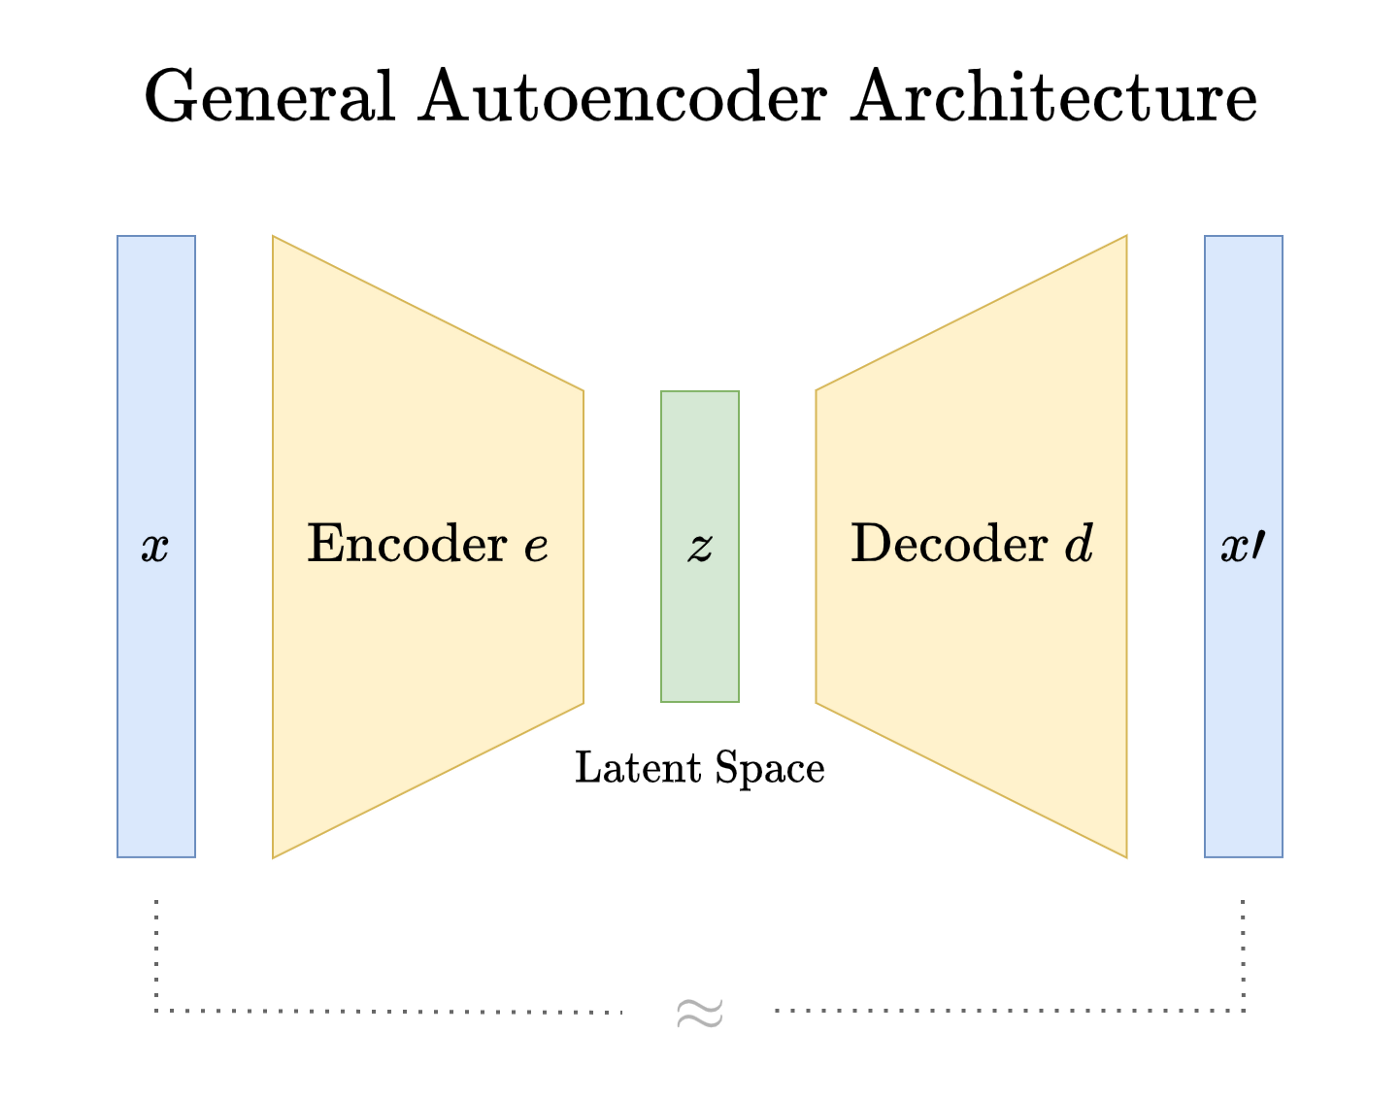

In [ ]:
dim_code = 16

Реализуем autoencoder. Архитектуру (conv, fully-connected, ReLu, etc) можете выбирать сами. Экспериментируйте!

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        # Энкодер (сжимает картинку 3x45x45 в вектор размера 16)
        self.encoder = nn.Sequential(
            # Вход: 3 канала, 45x45
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),  # выход: 32x23x23
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # выход: 64x12x12
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),# выход: 128x6x6
            nn.ReLU(),
            nn.Flatten(),                                          # вытягиваем в одномерный вектор 128*6*6 = 4608
            nn.Linear(128 * 6 * 6, dim_code)                       # сжимаем до dim_code (16)
        )

        # Декодер (восстанавливает вектор размера 16 обратно в картинку 3x45x45)
        self.decoder = nn.Sequential(
            nn.Linear(dim_code, 128 * 6 * 6),                      # разжимаем до 4608
            nn.Unflatten(1, (128, 6, 6)),                          # превращаем обратно в тензор 128x6x6
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1), # выход: 64x12x12
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=0),  # выход: 32x23x23
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=0),   # выход: 3x45x45
            nn.Sigmoid() # Сигмоида возвращает значения пикселей в диапазон от 0.0 до 1.0
        )
    def forward(self, x):
        # реализуйте forward проход автоэнкодера
        latent_code = self.encoder(x)
        reconstruction = self.decoder(latent_code)

        # в качестве возвращаемых переменных -- латентное представление картинки (latent_code)
        # и полученная реконструкция изображения (reconstruction)
        return reconstruction, latent_code

In [ ]:
criterion = nn.MSELoss()



autoencoder = Autoencoder()

optimizer = torch.optim.Adam(autoencoder.parameters(),lr=1e-3)

## 1.3 Обучение (2 балла)

Осталось написать код обучения автоэнкодера. При этом было бы неплохо в процессе иногда смотреть, как автоэнкодер реконструирует изображения на данном этапе обучения. Наример, после каждой эпохи (прогона train выборки через автоэнкодер) можно смотреть, какие реконструкции получились для каких-то изображений val выборки.

А, ну еще было бы неплохо выводить графики train и val лоссов в процессе тренировки =)

In [ ]:
epoch = 40

In [ ]:
with torch.no_grad():
  x = torch.randint(0, 24, (2,))
  for i in range(2):


      input_img = val_dataset[x[i]][0].unsqueeze(0)  # Добавляем размерность батча -> (1, C, H, W)
      outputs,_ = autoencoder(input_img)


      # Для matplotlib переводим (C, H, W) -> (H, W, C)
      img_to_show = outputs.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()

      plt.figure(figsize=(3, 3))
      plt.imshow(img_to_show)
      plt.axis('off')
      plt.title(f"Epoch {epoch + 1}")
      plt.show()

In [ ]:
from tqdm.notebook import tqdm

In [ ]:
epoch = 40

q = []
for ep in tqdm(range(epoch), desc="Obuchenie"):
  a = np.array([])
  autoencoder.train()
  for i,j in train_loader:
      optimizer.zero_grad()
      t,v = autoencoder(i)

      los = criterion(t,i)

      los.backward()

      optimizer.step()
      a = np.append(a,los.item())

  q.append(np.mean(a))
  autoencoder.eval()
  with torch.no_grad():
    x = torch.randint(0, 24, (2,))
    for i in range(2):


        input_img = val_dataset[x[i]][0].unsqueeze(0)  # Добавляем размерность батча -> (1, C, H, W)
        outputs,_ = autoencoder(input_img)


        # Для matplotlib переводим (C, H, W) -> (H, W, C)
        img_to_show = outputs.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()

        plt.figure(figsize=(3, 3))
        plt.imshow(img_to_show)
        plt.axis('off')
        plt.title(f"Epoch {epoch + 1}")
        plt.show()



In [ ]:
q

Давайте посмотрим, как наш тренированный автоэнкодер кодирует и восстанавливает картинки:

In [ ]:
for inputs, _ in val_loader:
    outputs, _ = autoencoder(inputs)


    # Для matplotlib переводим (C, H, W) -> (H, W, C)
    img_to_show = outputs[0].detach().cpu().permute(1, 2, 0).numpy()

    plt.figure(figsize=(3, 3))
    plt.imshow(img_to_show)
    plt.axis('off')
    plt.title(f"Epoch {epoch + 1}")
    plt.show()

NameError: name 'val_loader' is not defined

Что вы можете сказать про результат?

## 1.4. Sampling (2 балла)

Давайте теперь будем не просто брать картинку, прогонять ее через автоэнкодер и получать реконструкцию, а попробуем создать что-то НОВОЕ!

Давайте возьмем и подсунем декодеру какие-нибудь сгенерированные нами векторы (например, из нормального распределения) и посмотрим на результат реконструкции декодера:

__Подсказка:__ Если вместо лиц у вас выводится непонятно что, попробуйте посмотреть, как выглядят латентные векторы картинок из датасета. Так как в обучении нейронных сетей есть определенная доля рандома, векторы латентного слоя могут быть распределены НЕ как `np.random.randn(25, <latent_space_dim>)`. А чтобы у нас получались лица при запихивании вектора декодеру, вектор должен быть распределен так же, как латентные векторы реальных фоток. Так что в таком случае придется рандом немного подогнать.

In [ ]:
qw = autoencoder.decoder

In [ ]:
# сгенерируем 25 рандомных векторов размера latent_space
z = torch.Tensor(np.random.randn(25, 16))

output = qw(z)
for i in range(25):
  er = output[i].permute(1,2,0).detach().numpy()
  plt.figure(figsize=(2, 2))
  plt.imshow(er)
  plt.axis('off')
  # Выводим номер эпохи и средний loss
  plt.show()

## 1.5 Time to make fun! (3 балла)

Давайте научимся пририсовывать людям улыбки =)

<img src="https://i.imgur.com/tOE9rDK.png" alt="linear" width="700" height="400">

План такой:

1. Нужно выделить "вектор улыбки": для этого нужно из выборки изображений найти несколько (~15) людей с улыбками и столько же без.

Найти людей с улыбками вам поможет файл с атрибутами, скачанный вместе с картинками. В нем указаны имена изображений и присутствубщие атрибуты (улыбки, очки и прочее интересное).

2. Вычислить латентный вектор для всех улыбающихся людей (прогнать их через encoder) и то же для всех грустненьких.

3. Вычислить, собственно, вектор улыбки -- посчитать разность между средним латентным вектором улыбающихся людей и средним латентным вектором грустных людей.

4. А теперь приделаем улыбку грустному человеку: добавим полученный в пункте 3 вектор к латентному вектору грустного человека и прогоним полученный вектор через decoder. Получим того же человека, но уже не грустненького!

In [ ]:
X_train.shape

In [ ]:
qwe = attrs_train.sort_values(by="Smiling",ascending=False).head(25).index
qwe_sad = attrs_train.sort_values(by="Smiling",ascending=True).head(25).index


In [ ]:
attrs.loc[8643]["Smiling"]

In [ ]:
X_train[0].shape

In [ ]:
sqir = []
sqir_low = []
for i in range(25):
  try:
    x = X_train[qwe[i]].unsqueeze(0)
    x_low = X_train[qwe_sad[i]].unsqueeze(0)
  except:
    continue
  er,re = autoencoder(x)
  er_low,re_low = autoencoder(x_low)
  sqir.append(re)
  sqir_low.append(re_low)
  er = er.squeeze(0).permute(1,2,0).detach().numpy()

  plt.figure(figsize=(2, 2))
  plt.imshow(er)
  plt.axis('off')
  # Выводим номер эпохи и средний loss
  plt.show()


In [ ]:
vec = torch.stack(sqir,dim=1)
vec_low = torch.stack(sqir_low,dim=1)

In [ ]:
vec_mean = vec.mean(dim=1)
vec_mean_low = vec_low.mean(dim=1)

In [ ]:
with torch.no_grad():
  itog = vec_mean-vec_mean_low


In [ ]:
t1 = X_train[8]

In [ ]:
t2 = autoencoder.encoder(t1.unsqueeze(0))-5*itog

In [ ]:
t3 = autoencoder.decoder(t2).squeeze(0)

In [ ]:
er = t3.permute(1,2,0).detach().numpy()
plt.figure(figsize=(2, 2))
plt.imshow(er)
plt.axis('off')
# Выводим номер эпохи и средний loss
plt.show()

Вуаля! Вы восхитительны!

Теперь вы можете пририсовывать людям не только улыбки, но и много чего другого -- закрывать/открывать глаза, пририсовывать очки... В общем, все, на что хватит фантазии и на что есть атрибуты в `attrs`:)

In [ ]:
# 1. Получаем индексы
qwe = attrs_train.sort_values(by="Smiling", ascending=False).head(25).index
qwe_sad = attrs_train.sort_values(by="Smiling", ascending=True).head(25).index

sqir = []
sqir_low = []

# Выключаем градиенты для ВСЕГО процесса
with torch.no_grad():
    for i in range(25):
        try:
            x = X_train[qwe[i]].unsqueeze(0)
            x_low = X_train[qwe_sad[i]].unsqueeze(0)
        except:
            continue

        # 2. Вычисляем латентные векторы
        er, re = autoencoder(x)
        er_low, re_low = autoencoder(x_low)

        sqir.append(re)
        sqir_low.append(re_low)

    # 3. Вычисляем вектор улыбки
    # Объединяем списки по размерности батча -> получаем (N, 16, H, W) или (N, 16)
    vec = torch.cat(sqir, dim=0)
    vec_low = torch.cat(sqir_low, dim=0)

    # Считаем среднее по нулевой оси (по всем людям), сохраняя размерность (1, ...)
    vec_mean = vec.mean(dim=0, keepdim=True)
    vec_mean_low = vec_low.mean(dim=0, keepdim=True)

    # ВЕКТОР УЛЫБКИ
    smile_vector = vec_mean - vec_mean_low

    # ==========================================
    # 4. ПРИДЕЛЫВАЕМ УЛЫБКУ ГРУСТНОМУ ЧЕЛОВЕКУ
    # ==========================================

    # Берем латентный вектор первого грустного человека из нашего списка
    sad_person_latent = sqir_low[0]

    # Прибавляем "вектор улыбки" (можно умножить на коэффициент, например * 1.5, чтобы усилить эффект)
    smiling_person_latent = sad_person_latent + smile_vector

    # Прогоняем модифицированный вектор только через декодер
    smiling_reconstruction = autoencoder.decoder(smiling_person_latent)

    # Подготавливаем картинки для сравнения
    original_sad_img = x_low_example = X_train[qwe_sad[0]].permute(1, 2, 0).cpu().numpy()
    new_smiling_img = smiling_reconstruction.squeeze(0).permute(1, 2, 0).cpu().numpy()

    # Ограничиваем значения пикселей [0, 1] для корректного отображения
    new_smiling_img = torch.clamp(torch.tensor(new_smiling_img), 0, 1).numpy()

    # Отрисовываем До и После
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))

    axes[0].imshow(original_sad_img)
    axes[0].set_title("Оригинал (Грустный)")
    axes[0].axis('off')

    axes[1].imshow(new_smiling_img)
    axes[1].set_title("С улыбкой (+ smile vector)")
    axes[1].axis('off')

    plt.show()

# Часть 2: Variational Autoencoder (10 баллов)

Займемся обучением вариационных автоэнкодеров — проапгрейженной версии AE. Обучать будем на датасете MNIST, содержащем написанные от руки цифры от 0 до 9

In [ ]:
import torchvision.transforms.v2 as v2

In [ ]:
batch_size = 32
# MNIST Dataset
transform_pipeline = v2.Compose([
    v2.ToImage(),                  # Конвертирует в специальный Image-тензор без деления на 255
    v2.ToDtype(torch.float32, scale=True)
])
train_dataset = datasets.MNIST(root='./mnist_data/', train=True, transform=transform_pipeline, download=True)
test_dataset = datasets.MNIST(root='./mnist_data/', train=False, transform=transform_pipeline, download=False)

# Data Loader (Input Pipeline)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.96MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.9MB/s]


## 2.1 Архитектура модели и обучение (2 балла)

Реализуем VAE. Архитектуру (conv, fully-connected, ReLu, etc) можете выбирать сами. Рекомендуем пользоваться более сложными моделями, чем та, что была на семинаре:) Экспериментируйте!

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
from tqdm.notebook import tqdm

In [ ]:
latent_dim = 64

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE, self).__init__()

        # ==========================================
        # 1. ENCODER (Сверточная часть)
        # Вход: (Batch, 1, 28, 28)
        # ==========================================
        self.encoder_cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),  # -> [B, 32, 14, 14]
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # -> [B, 64, 7, 7]
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1), # -> [B, 128, 4, 4]
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten() # -> Вытягиваем в вектор: 128 * 4 * 4 = 2048
        )

        # Два "хвоста" энкодера для параметров распределения
        self.fc_m = nn.Linear(2048, latent_dim)
        self.fc_sig = nn.Linear(2048, latent_dim)

        # ==========================================
        # 2. DECODER
        # ==========================================
        # Проекция из латентного пространства обратно в тензор признаков
        self.fc_dec = nn.Linear(latent_dim, 2048)
        self.unf = nn.Unflatten(1, (128, 4, 4))

        self.decoder_cnn = nn.Sequential(
            # Вход после reshape будет: [B, 128, 4, 4]
            # output_padding=0 дает размер 7
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=0), # -> [B, 64, 7, 7]
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # output_padding=1 дает размер 14
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),  # -> [B, 32, 14, 14]
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),

            # output_padding=1 дает итоговый размер 28
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),   # -> [B, 1, 28, 28]
            nn.Sigmoid() # Жмем пиксели в диапазон [0, 1]
        )

    def encode(self, x):
        t = self.encoder_cnn(x)
        # ИСПРАВЛЕНО: передаем t (признаки), а не x (исходную картинку)
        mu = self.fc_m(t)
        logsigma = self.fc_sig(t)
        return mu, logsigma

    def gaussian_sampler(self, mu, logsigma):
        if self.training:
            sigma = torch.exp(0.5 * logsigma)
            t = torch.randn_like(sigma)
            return mu + (t * sigma)
        else:
            # на инференсе возвращаем не случайный вектор из нормального распределения, а математическое ожидание -- mu.
            return mu

    def decode(self, z):
        t1 = self.fc_dec(z)
        t1 = self.unf(t1)
        reconstruction = self.decoder_cnn(t1)
        return reconstruction

    def forward(self, x):
        mu, sig = self.encode(x)
        e = self.gaussian_sampler(mu, sig)
        reconstruction = self.decode(e)
        return mu, sig, reconstruction

Определим лосс и его компоненты для VAE:

Надеюсь, вы уже прочитали материал в towardsdatascience (или еще где-то) про VAE и знаете, что лосс у VAE состоит из двух частей: KL и log-likelihood.

Общий лосс будет выглядеть так:

$$\mathcal{L} = -D_{KL}(q_{\phi}(z|x)||p(z)) + \log p_{\theta}(x|z)$$

Формула для KL-дивергенции:

$$D_{KL} = -\frac{1}{2}\sum_{i=1}^{dimZ}(1+log(\sigma_i^2)-\mu_i^2-\sigma_i^2)$$

В качестве log-likelihood возьмем привычную нам кросс-энтропию.

In [ ]:
t = torch.tensor([1,2,3],dtype=torch.float32)
t2 = torch.tensor([1,1,1],dtype=torch.float32)

tensor(8.0774)

In [ ]:
def KL_divergence(mu, logsigma):
    """
    часть функции потерь, которая отвечает за "близость" латентных представлений разных людей
    """
    loss = loss = -0.5 * torch.sum(1 + logsigma - torch.pow(mu, 2) - torch.exp(logsigma))

    return loss

In [ ]:
def KL_divergence(mu, logsigma):
    """
    часть функции потерь, которая отвечает за "близость" латентных представлений разных людей
    """
    loss = -1/2 * torch.sum(1+logsigma-torch.pow(mu,2)-torch.exp(logsigma))

    return loss

def log_likelihood(x, reconstruction):
    """
    часть функции потерь, которая отвечает за качество реконструкции (как mse в обычном autoencoder)
    """
    loss = F.binary_cross_entropy(reconstruction, x, reduction='sum')
    return loss

def loss_vae(x, mu, logsigma, reconstruction):
    kl = KL_divergence(mu, logsigma)
    recon_loss = log_likelihood(x, reconstruction)

    return (recon_loss + kl)/x.size(0)

И обучим модель:

In [ ]:
criterion = loss_vae

autoencoder = VAE()
autoencoder = autoencoder.to(device)
optimizer = optim.Adam(autoencoder.parameters(),lr = 1e-3)

In [ ]:
t = [1,2,3]
print(np.mean(t))

2.0


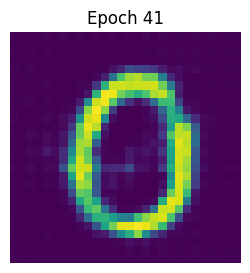

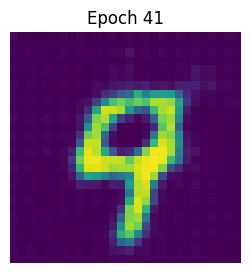

In [ ]:
x = torch.randint(0, 24, (2,))
for i in range(2):
    input_img = test_dataset[x[i]][0].unsqueeze(0)  # Добавляем размерность батча -> (1, C, H, W)
    _,_,outputs= autoencoder(input_img)


    # Для matplotlib переводим (C, H, W) -> (H, W, C)
    img_to_show = outputs.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()

    plt.figure(figsize=(3, 3))
    plt.imshow(img_to_show)
    plt.axis('off')
    plt.title(f"Epoch {epoch + 1}")
    plt.show()

In [ ]:
epoch = 40

In [ ]:
test_dataset[11][1]

6

  0%|          | 0/40 [00:00<?, ?it/s]

2


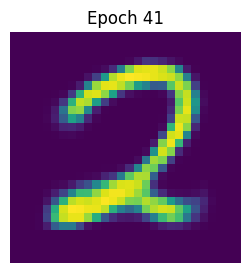

7


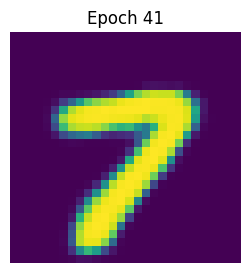

3461.6728098958333 2998.9551561251997
2


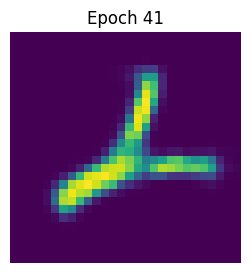

3


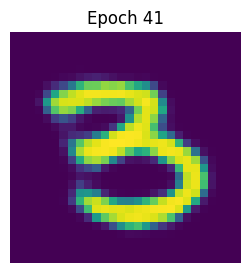

3403.9279057291665 2959.6329685003993
3


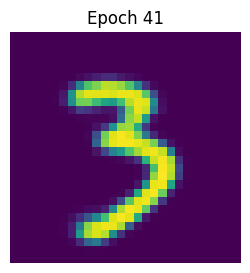

6


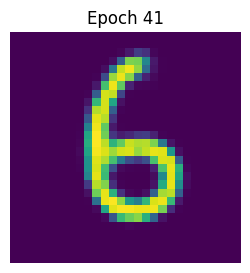

3367.2390915364585 2982.9492675001247
7


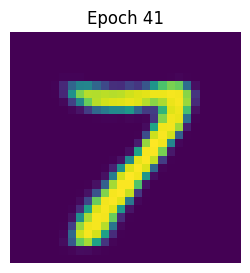

1


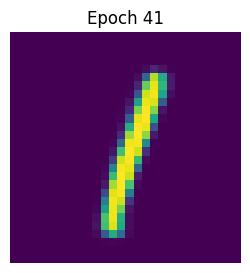

3338.90494609375 2959.125295620757
5


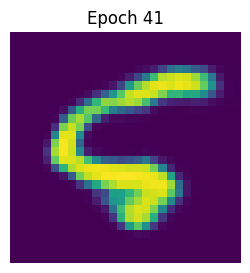

1


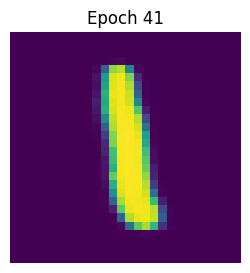

3315.27420625 2918.872613973892
6


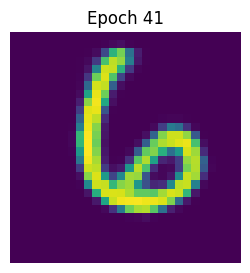

3


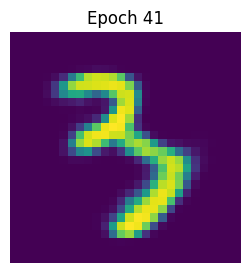

3299.177079296875 2935.997078892522
1


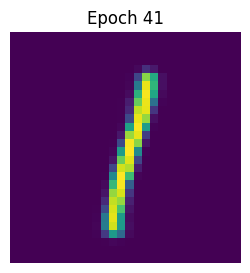

3


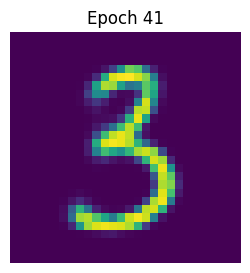

3281.8472122395833 2893.3677842015277
9


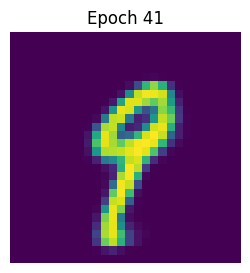

8


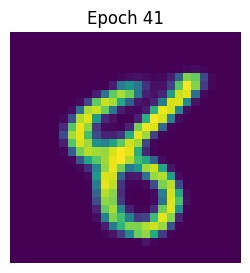

3270.427492447917 2888.2215061370557
7


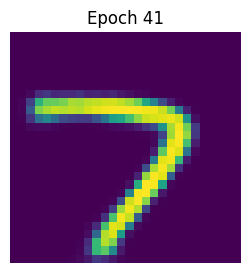

3


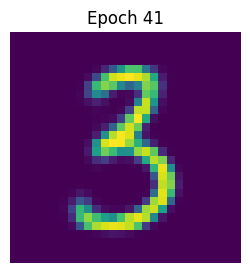

3259.308232682292 2896.7359841441194
7


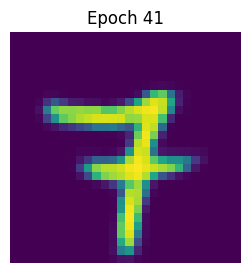

8


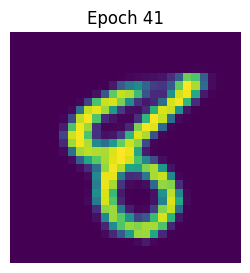

3247.730651432292 2901.762731582593
7


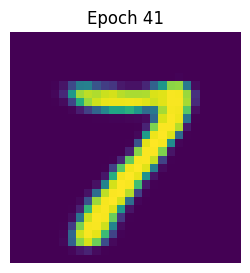

5


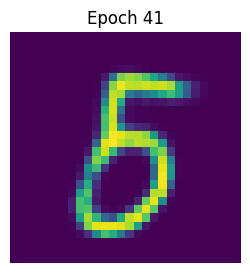

3240.5363859375 2882.2057629667534
6


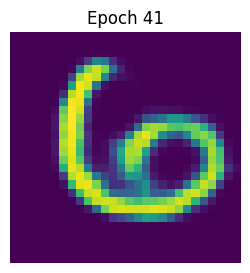

7


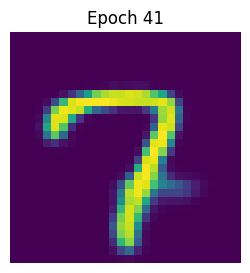

3233.294001171875 2878.5674303926216
7


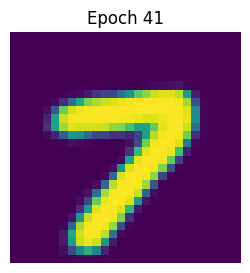

1


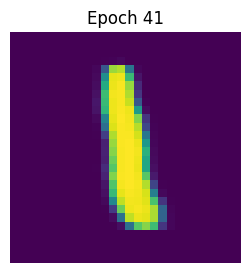

3227.024393229167 2885.243917154428
3


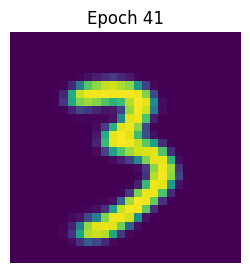

7


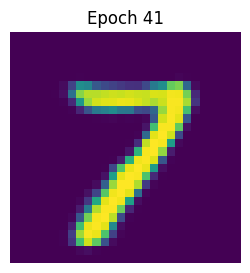

3218.336336328125 2889.217580777007
1


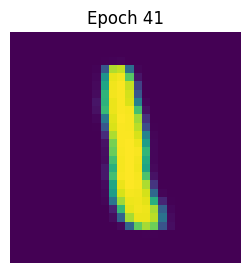

4


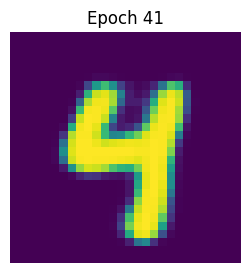

3212.503159765625 2851.698439918006
1


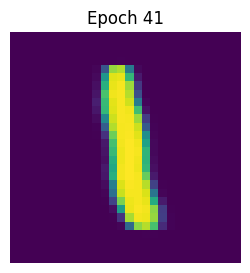

7


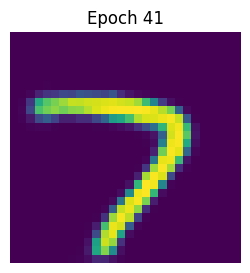

3206.7294404947916 2866.0383016080523
9


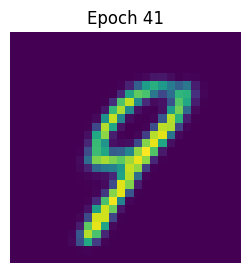

1


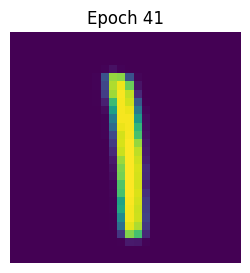

3201.9869364583333 2864.0692567672972
5


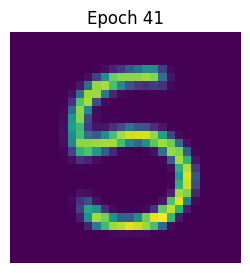

9


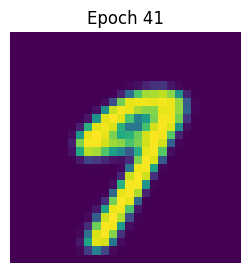

3199.55634453125 2864.887353281624
5


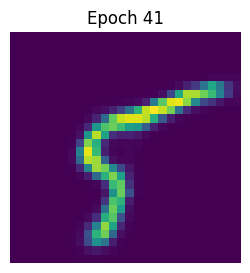

1


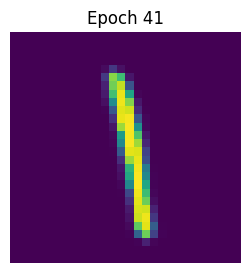

3194.0424553385415 2872.6905755478733
7


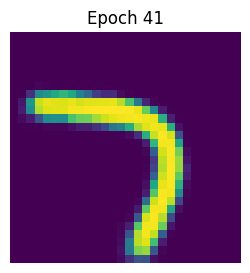

9


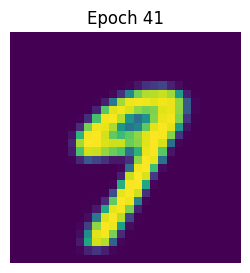

3191.350484765625 2851.500047970123
0


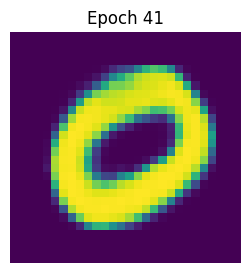

5


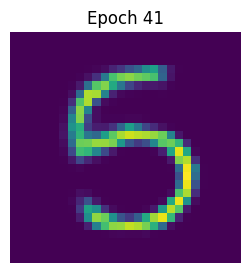

3186.1464184895835 2868.489044871955
2


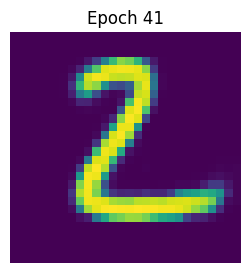

7


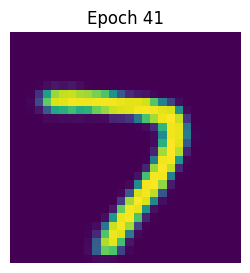

3182.6952506510415 2842.054440239367
6


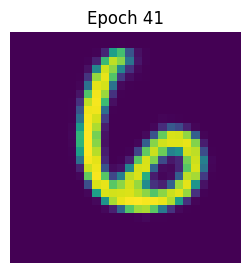

1


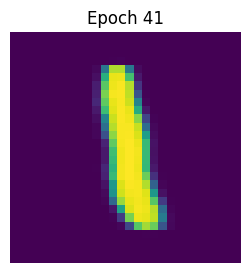

3178.958482421875 2847.0253075547876
2


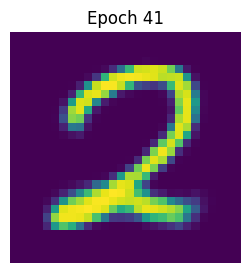

6


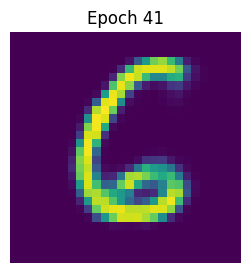

3175.250864583333 2864.644812050719
8


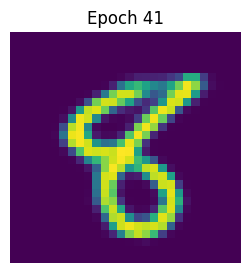

3


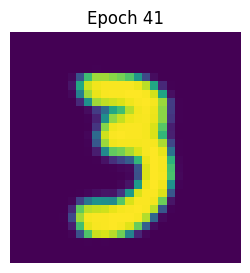

3173.000088151042 2847.4531433300467


KeyboardInterrupt: 

In [ ]:
яq = []
q1 = []
for ass in tqdm(range(epoch)):
  t = []
  t2 = []
  autoencoder.train()
  for i,j in train_loader:
    i = i.to(device)
    optimizer.zero_grad()
    mu,sig,rec = autoencoder(i)
    los = criterion(i,mu,sig,rec)
    los.backward()
    optimizer.step()
    t.append(los.item())
  q.append(np.mean(t))
  autoencoder.eval()
  with torch.no_grad():
    for i1,j1 in test_loader:
      i1 = i1.to(device)
      mu,sig,rec = autoencoder(i1)
      los = criterion(i1,mu,sig,rec)

      t2.append(los.item())
  q1.append(np.mean(t2))
  x = torch.randint(0, 100, (2,))

  for i2 in range(2):
    input_img = test_dataset[x[i2]][0].unsqueeze(0).to(device)  # Добавляем размерность батча -> (1, C, H, W)
    _,_,outputs= autoencoder(input_img)


    # Для matplotlib переводим (C, H, W) -> (H, W, C)
    img_to_show = outputs.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    print(test_dataset[x[i2]][1])
    plt.figure(figsize=(3, 3))
    plt.imshow(img_to_show)
    plt.axis('off')
    plt.title(f"Epoch {epoch + 1}")
    plt.show()
  print(np.mean(t),np.mean(t2))

Давайте посмотрим, как наш тренированный VAE кодирует и восстанавливает картинки:

In [ ]:
with torch.no_grad():
    for i1,j1 in test_loader:
      input_img = test_dataset[x[i2]][0].unsqueeze(0).to(device)  # Добавляем размерность батча -> (1, C, H, W)
      _,_,outputs= autoencoder(i1)


      # Для matplotlib переводим (C, H, W) -> (H, W, C)
      img_to_show = outputs.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
      print(test_dataset[x[i2]][1])
      plt.figure(figsize=(3, 3))
      plt.imshow(img_to_show)
      plt.axis('off')
      plt.title(f"Epoch {epoch + 1}")
      plt.show()




RuntimeError: permute(sparse_coo): number of dimensions in the tensor input does not match the length of the desired ordering of dimensions i.e. input.dim() = 4 is not equal to len(dims) = 3

Давайте попробуем проделать для VAE то же, что и с обычным автоэнкодером -- подсунуть decoder'у из VAE случайные векторы из нормального распределения и посмотреть, какие картинки получаются:

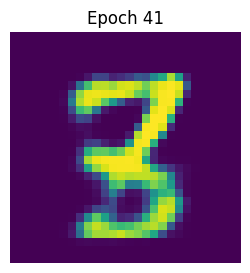

In [ ]:
# вспомните про замечание из этого же пункта обычного AE про распределение латентных переменных
autoencoder.eval()

with torch.no_grad():
  z = torch.randn(1, latent_dim).to(device)
  output = autoencoder.decode(z)
  img_to_show = output.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
  plt.figure(figsize=(3, 3))
  plt.imshow(img_to_show)
  plt.axis('off')
  plt.title(f"Epoch {epoch + 1}")
  plt.show()


## 2.2. Latent Representation (2 балла)

Давайте посмотрим, как латентные векторы картинок лиц выглядят в пространстве.
Ваша задача -- изобразить латентные векторы картинок точками в двумерном просторанстве.

Это позволит оценить, насколько плотно распределены латентные векторы изображений цифр в пространстве.

Плюс давайте сделаем такую вещь: покрасим точки, которые соответствуют картинкам каждой цифры, в свой отдельный цвет

Подсказка: красить -- это просто =) У plt.scatter есть параметр c (color), см. в документации.


Итак, план:
1. Получить латентные представления картинок тестового датасета
2. С помощтю `TSNE` (есть в `sklearn`) сжать эти представления до размерности 2 (чтобы можно было их визуализировать точками в пространстве)
3. Визуализировать полученные двумерные представления с помощью `matplotlib.scatter`, покрасить разными цветами точки, соответствующие картинкам разных цифр.

In [ ]:
<ваш код получения латентных представлений, применения TSNE и визуализации>

Что вы думаете о виде латентного представления?

__Congrats v2.0!__

## 2.3. Conditional VAE (6 баллов)


Мы уже научились обучать обычный AE на датасете картинок и получать новые картинки, используя генерацию шума и декодер.
Давайте теперь допустим, что мы обучили AE на датасете MNIST и теперь хотим генерировать новые картинки с числами с помощью декодера (как выше мы генерили рандомные лица).
И вот нам понадобилось сгенерировать цифру 8, и мы подставляем разные варианты шума, но восьмерка никак не генерится:(

Хотелось бы добавить к нашему AE функцию "выдай мне рандомное число из вот этого вот класса", где классов десять (цифры от 0 до 9 образуют десять классов).  Conditional AE — так называется вид автоэнкодера, который предоставляет такую возможность. Ну, название "conditional" уже говорит само за себя.

И в этой части задания мы научимся такие обучать.

### Архитектура

На картинке ниже представлена архитектура простого Conditional VAE.

По сути, единственное отличие от обычного -- это то, что мы вместе с картинкой в первом слое энкодера и декодера передаем еще информацию о классе картинки.

То есть, в первый (входной) слой энкодера подается конкатенация картинки и информации о классе (например, вектора из девяти нулей и одной единицы). В первый слой декодера подается конкатенация латентного вектора и информации о классе.


![alt text](https://sun9-63.userapi.com/impg/Mh1akf7mfpNoprrSWsPOouazSmTPMazYYF49Tw/djoHNw_9KVA.jpg?size=1175x642&quality=96&sign=e88baec5f9bb91c8443fba31dcf0a4df&type=album)

![alt text](https://sun9-73.userapi.com/impg/UDuloLNKhzTBYAKewgxke5-YPsAKyGOqA-qCRg/MnyCavJidxM.jpg?size=1229x651&quality=96&sign=f2d21bfacc1c5755b76868dc4cfef39c&type=album)



На всякий случай: это VAE, то есть, latent у него все еще состоит из mu и sigma

Таким образом, при генерации новой рандомной картинки мы должны будем передать декодеру сконкатенированные латентный вектор и класс картинки.

P.S. Также можно передавать класс картинки не только в первый слой, но и в каждый слой сети. То есть на каждом слое конкатенировать выход из предыдущего слоя и информацию о классе.

In [ ]:
model = ConditionalVAE().to(device)

In [ ]:
optimizer = optim.Adam(model.parameters(),lr = 1e-3)

In [ ]:
class ConditionalVAE(nn.Module):
    def __init__(self, latent_dim=64, num_classes=10):
        super(ConditionalVAE, self).__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes

        # Слой для автоматического выравнивания входящего тензора
        self.flatten = nn.Flatten()

        # --- ЭНКОДЕР ---
        # 784 (28*28 пикселей) + 10 (one-hot вектор класса)
        self.enc_fc1 = nn.Linear(784 + num_classes, 512)
        self.enc_fc2 = nn.Linear(512, 256)

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        # --- ДЕКОДЕР ---
        self.dec_fc1 = nn.Linear(latent_dim + num_classes, 256)
        self.dec_fc2 = nn.Linear(256, 512)
        self.dec_fc3 = nn.Linear(512, 784)

    def encode(self, x, y):
        # Если пришла 4D картинка (B, C, H, W), превращаем её в (B, 784)
        x_flat = self.flatten(x)

        # Конкатенация выпрямленной картинки и вектора класса по оси признаков
        x_cond = torch.cat([x_flat, y], dim=1)

        h = F.relu(self.enc_fc1(x_cond))
        h = F.relu(self.enc_fc2(h))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z, y):
        # Конкатенация латентного вектора z и вектора класса y
        z_cond = torch.cat([z, y], dim=1)

        h = F.relu(self.dec_fc1(z_cond))
        h = F.relu(self.dec_fc2(h))

        # Получаем плоский вектор размерности (B, 784) с элементами [0, 1]
        rec_flat = torch.sigmoid(self.dec_fc3(h))

        # Возвращаем к исходному размеру изображения (B, 1, 28, 28)
        rec = rec_flat.view(-1, 1, 28, 28)
        return rec

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = self.reparameterize(mu, logvar)
        rec = self.decode(z, y)
        return mu, logvar, rec

In [ ]:
for _ in tqdm(range(epoch)):
    t = []
    for i, j in train_loader:
        i = i.to(device) # Формат: (B, 1, 28, 28) — руками менять shape больше не нужно!

        # Кодируем числовую метку j в one-hot вектор
        y_one_hot = F.one_hot(j, num_classes=10).float().to(device)

        optimizer.zero_grad()
        mu, sig, rec = model(i, y_one_hot)

        loss = criterion(i, mu, sig, rec)
        t.append(loss.item())
        loss.backward()
        optimizer.step()

    print(np.mean(t))

  0%|          | 0/40 [00:00<?, ?it/s]

145.10929717610676
114.07022016601563
108.16569368896485
105.19068181966146
103.48604197184245
102.29298453776042
101.38442791341146
100.71151126708985
100.14316454264323
99.63475133870443
99.21036235758463
98.84920851236978
98.53857438151041
98.23188472900391
97.99062116699218
97.75189935302734


KeyboardInterrupt: 

### Sampling

Тут мы будем сэмплировать из CVAE. Это прикольнее, чем сэмплировать из простого AE/VAE: тут можно взять один и тот же латентный вектор и попросить CVAE восстановить из него картинки разных классов!
Для MNIST вы можете попросить CVAE восстановить из одного латентного вектора, например, картинки цифры 5 и 7.

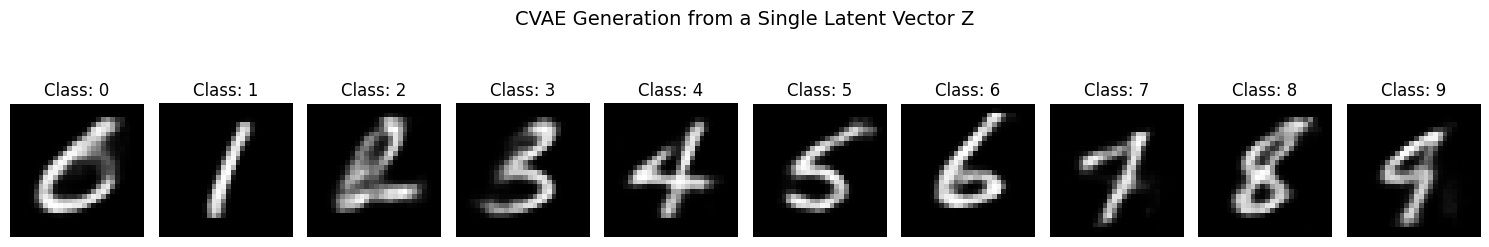

In [ ]:
# Переводим модель в режим вычисления (отключаем Dropout/BatchNorm, если есть)
model.eval()

num_classes = 10
# Берем ОДИН фиксированный латентный вектор z для всех классов
# Размерность латентного пространства (latent_dim) задана при инициализации модели (например, 64)
z_fixed = torch.randn(1, model.latent_dim).to(device)

plt.figure(figsize=(15, 3))

with torch.no_grad():
    for digit in range(num_classes):
        # Формируем one-hot вектор для текущей цифры
        y_digit = torch.tensor([digit]).to(device)
        y_one_hot = F.one_hot(y_digit, num_classes=num_classes).float()

        # Декодируем один и тот же z с разной меткой класса
        generated_img = model.decode(z_fixed, y_one_hot)

        # Подготавливаем изображение к отрисовке (B, C, H, W) -> (H, W)
        img_np = generated_img.squeeze().cpu().numpy()

        # Отрисовываем сетку из 10 цифр
        plt.subplot(1, num_classes, digit + 1)
        plt.imshow(img_np, cmap='gray')
        plt.title(f"Class: {digit}")
        plt.axis('off')

plt.suptitle("CVAE Generation from a Single Latent Vector Z", fontsize=14)
plt.tight_layout()
plt.show()

Splendid! Вы великолепны!


### Latent Representations

Давайте посмотрим, как выглядит латентное пространство картинок в CVAE и сравним с картинкой для VAE =)

Опять же, нужно покрасить точки в разные цвета в зависимости от класса.

In [ ]:
<ваш код получения латентных представлений, применения TSNE и визуализации>

Что вы думаете насчет этой картинки? Отличается от картинки для VAE?

# BONUS 1: Denoising (2 балла)



У автоэнкодеров, кроме сжатия и генерации изображений, есть другие практические применения. Про одно из них эта бонусная часть задания.

Автоэнкодеры могут быть использованы для избавления от шума на фотографиях (denoising). Для этого их нужно обучить специальным образом: input картинка будет зашумленной, а выдавать автоэнкодер должен будет картинку без шума.
То есть, loss-функция AE останется той же (MSE между реальной картинкой и выданной), а на вход автоэнкодеру будет подаваться зашумленная картинка.

<a href="https://ibb.co/YbRJ1nZ"><img src="https://i.ibb.co/0QD164t/Screen-Shot-2020-06-04-at-4-49-50-PM.png" alt="Screen-Shot-2020-06-04-at-4-49-50-PM" border="0"></a>

Для этого нужно взять ваш любимый датасет (датасет лиц из первой части этого задания или любой другой) и сделать копию этого датасета с шумом.

В питоне шум можно добавить так:

In [ ]:
criterion = loss_vae

autoencoder = VAE()
autoencoder = autoencoder.to(device)
optimizer = optim.Adam(autoencoder.parameters(),lr = 1e-3)

In [ ]:
epoch = 25

  0%|          | 0/25 [00:00<?, ?it/s]

5


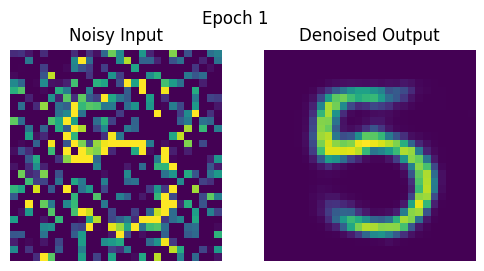

6


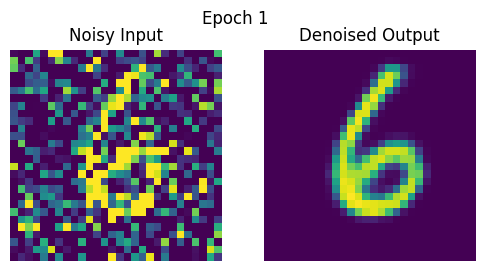

117.89647331542969 106.28068459605257
2


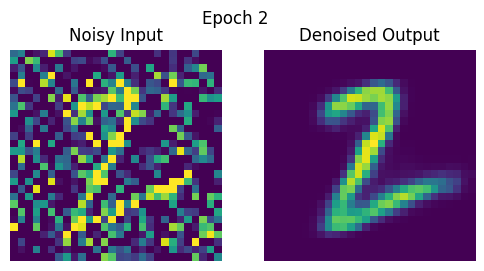

7


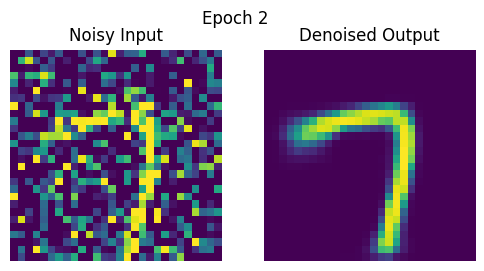

116.78062381184895 105.48255442658933
4


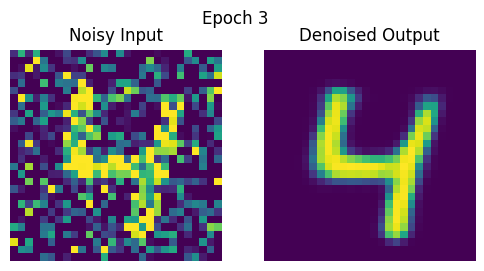

4


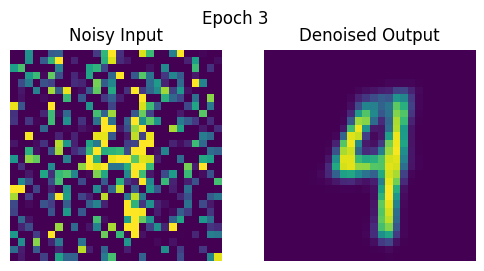

116.0599524210612 105.11660045099715
3


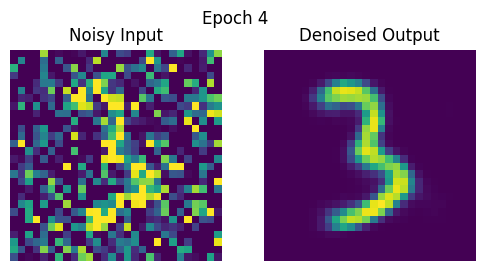

7


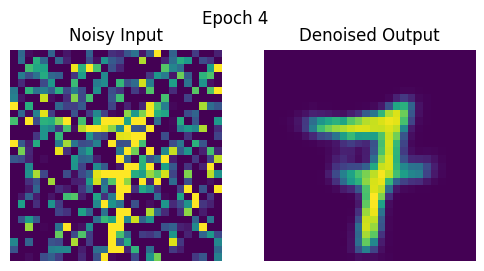

115.2455904337565 104.84755082785512
1


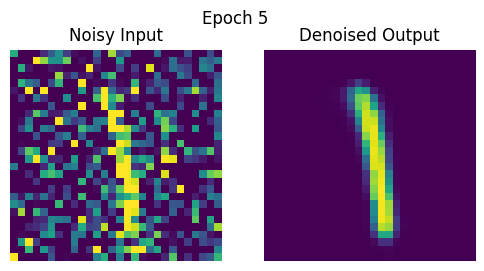

2


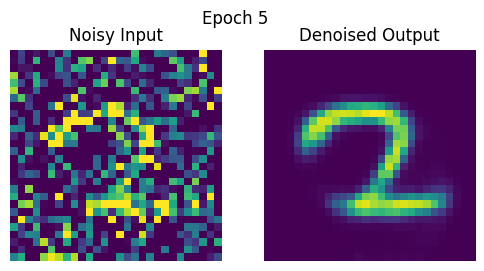

114.75869614257813 103.88841025745526
6


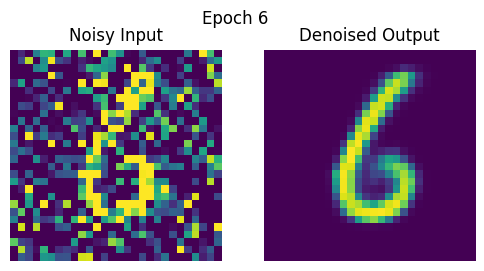

6


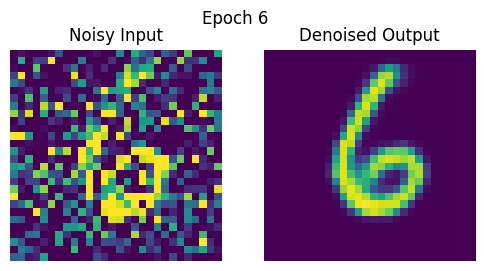

114.33443566894532 104.44408463060665


KeyboardInterrupt: 

In [ ]:
q = []
q1 = []
for ass in tqdm(range(epoch)):
  t = []
  t2 = []
  autoencoder.train()
  for i,j in train_loader:

    i = i.to(device)
    noise_factor = 0.5

    i1 = torch.clamp(i + noise_factor * torch.randn_like(i), 0.0, 1.0)
    optimizer.zero_grad()
    mu,sig,rec = autoencoder(i1)
    los = criterion(i,mu,sig,rec)
    los.backward()
    optimizer.step()
    t.append(los.item())
  q.append(np.mean(t))
  autoencoder.eval()
  with torch.no_grad():
    for i1,j1 in test_loader:
      i1 = i1.to(device)
      i_test_noisy = torch.clamp(i1 + noise_factor * torch.randn_like(i1), 0.0, 1.0)
      mu,sig,rec = autoencoder(i_test_noisy)
      los = criterion(i1,mu,sig,rec)

      t2.append(los.item())
  q1.append(np.mean(t2))
  x = torch.randint(0, 100, (2,))

  for i2 in range(2):
    input_img = test_dataset[x[i2]][0].unsqueeze(0).to(device)  # Добавляем размерность батча -> (1, C, H, W)
    noise_factor = 0.5
    input_img = torch.clamp(input_img + noise_factor * torch.randn_like(input_img), 0.0, 1.0)

    _,_,outputs= autoencoder(input_img)


    # Для matplotlib переводим (C, H, W) -> (H, W, C)
    img_to_show = outputs.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    img_to_show1 = input_img.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    print(test_dataset[x[i2]][1])
    plt.figure(figsize=(6, 3))

# Зашумлённый вход
    plt.subplot(1, 2, 1)
    plt.imshow(img_to_show1.squeeze()) # .squeeze() защитит от багов с (H, W, 1)
    plt.title("Noisy Input")
    plt.axis('off')

    # Восстановленный выход
    plt.subplot(1, 2, 2)
    plt.imshow(img_to_show.squeeze())
    plt.title("Denoised Output")
    plt.axis('off')

    plt.suptitle(f"Epoch {ass + 1}")
    plt.show()
  print(np.mean(t),np.mean(t2))

In [ ]:
<тут проверка, как AE убирает шум с тестовых картинок. Надеюсь, все получилось =)>

# BONUS 2: Image Retrieval (2 балла)



Давайте представим, что весь наш тренировочный датасет -- это большая база данных людей. И вот мы получили картинку лица какого-то человека с уличной камеры наблюдения (у нас это картинка из тестового датасета) и хотим понять, что это за человек. Что нам делать? Правильно -- берем наш VAE, кодируем картинку в латентное представление и ищем среди латентных представлений лиц нашей базы самые ближайшие!

План:

1. Получаем латентные представления всех лиц тренировочного датасета
2. Обучаем на них LSHForest `(sklearn.neighbors.LSHForest)`, например, с `n_estimators=50`
3. Берем картинку из тестового датасета, с помощью VAE получаем ее латентный вектор
4. Ищем с помощью обученного LSHForest ближайшие из латентных представлений тренировочной базы
5. Находим лица тренировочного датасета, которым соответствуют ближайшие латентные представления, визуализируем!

Немного кода вам в помощь: (feel free to delete everything and write your own)

In [ ]:
codes = <поучите латентные представления картинок из трейна>

In [ ]:
# обучаем LSHForest
from sklearn.neighbors import LSHForest
lshf = LSHForest(n_estimators=50).fit(codes)

In [ ]:
def get_similar(image, n_neighbors=5):
  # функция, которая берет тестовый image и с помощью метода kneighbours у LSHForest ищет ближайшие векторы
  # прогоняет векторы через декодер и получает картинки ближайших людей

  code = <получение латентного представления image>

  (distances,),(idx,) = lshf.kneighbors(code, n_neighbors=n_neighbors)

  return distances, X_train[idx]

In [ ]:
def show_similar(image):

  # функция, которая принимает тестовый image, ищет ближайшие к нему и визуализирует результат

    distances,neighbors = get_similar(image,n_neighbors=11)

    plt.figure(figsize=[8,6])
    plt.subplot(3,4,1)
    plt.imshow(image.cpu().numpy().transpose([1,2,0]))
    plt.title("Original image")

    for i in range(11):
        plt.subplot(3,4,i+2)
        plt.imshow(neighbors[i].cpu().numpy().transpose([1,2,0]))
        plt.title("Dist=%.3f"%distances[i])
    plt.show()

In [ ]:
<тут выведите самые похожие лица к какому-нибудь лицу из тестовой части датасета>